**Analyse RH & demographique**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Audit et nettoyage des donnees**

In [4]:

# 1- Chargement des données
df = pd.read_csv("J23_dataset_employes.csv")

# 2- Les dimensions initiales
print("Dimensions initiales :", df.shape)

# 3- Audit des colonnes
audit = pd.DataFrame({"type": df.dtypes.astype(str),"valeurs_manquantes": df.isna().sum(),
    "pourcentage_manquant": (
        df.isna().mean() * 100
    ).round(2),
    "valeurs_distinctes": df.nunique()})

display(
    audit.sort_values(by="valeurs_manquantes",ascending=False))

# 4- Vérification des doublons
print("Nombre de doublons exacts est :", df.duplicated().sum())

display(df[df.duplicated(keep=False)])


Dimensions initiales : (655, 17)


,type,valeurs_manquantes,pourcentage_manquant,valeurs_distinctes
satisfaction_score,float64,13,1.98,65
education,str,11,1.68,5
performance_score,float64,9,1.37,36
city,str,8,1.22,14
role,str,5,0.76,18
employee_id,str,0,0.00,650
department,str,0,0.00,6
age,int64,0,0.00,39
gender,str,0,0.00,6
hire_date,str,0,0.00,619


Nombre de doublons exacts est : 5


,employee_id,age,gender,city,education,department,role,years_experience,hire_date,weekly_hours,overtime_hours,remote_days,monthly_salary_mad,performance_score,satisfaction_score,contract_type,promoted_last_2y
19,EMP0134,37,Homme,Tanger,Doctorat,Sales,Sales Analyst,0,2026-06-26,46,2.2,1,12850,2.9,6.8,CDD,Non
120,EMP0323,33,Femme,Rabat,Master,Sales,Sales Representative,5,2020-08-05,47,0.9,1,11300,3.1,6.8,CDI,Non
144,EMP0265,29,Femme,Tanger,Licence,Finance,Financial Analyst,0,2024-03-06,42,5.3,1,12150,3.7,6.5,CDI,Non
188,EMP0323,33,Femme,Rabat,Master,Sales,Sales Representative,5,2020-08-05,47,0.9,1,11300,3.1,6.8,CDI,Non
266,EMP0265,29,Femme,Tanger,Licence,Finance,Financial Analyst,0,2024-03-06,42,5.3,1,12150,3.7,6.5,CDI,Non
271,EMP0149,52,Homme,NaN,Bac,Data,Data Engineer,11,2015-10-18,44,5.7,0,19850,3.7,6.6,CDD,Non
294,EMP0134,37,Homme,Tanger,Doctorat,Sales,Sales Analyst,0,2026-06-26,46,2.2,1,12850,2.9,6.8,CDD,Non
338,EMP0197,29,Homme,agadir,Master,Data,Data Engineer,1,2024-05-14,46,5.0,1,16850,3.4,6.5,CDI,Non
406,EMP0149,52,Homme,NaN,Bac,Data,Data Engineer,11,2015-10-18,44,5.7,0,19850,3.7,6.6,CDD,Non
423,EMP0197,29,Homme,agadir,Master,Data,Data Engineer,1,2024-05-14,46,5.0,1,16850,3.4,6.5,CDI,Non


In [5]:

# 1- creer une copie df_clean
df_clean = df.drop_duplicates().copy()

# 2- Nettoyer les espaces dans les colonnes catégorielles
colonnes_texte = ["education", "department", "role","contract_type", "promoted_last_2y"]

for col in colonnes_texte:
    df_clean[col] = (df_clean[col].astype("string").str.strip())

# 3- Uniformiser les villes
ville_map = {
    "casablanca": "Casablanca",
    "rabat": "Rabat",
    "marrakech": "Marrakech","marrakesh": "Marrakech",
    "tanger": "Tanger",
    "fès": "Fès","fes": "Fès",
    "agadir": "Agadir"}

df_clean["city"] = (
    df_clean["city"].astype("string").str.strip().str.lower().map(ville_map))

# 4- Uniformiser le genre
genre_map = {"homme": "Homme","femme": "Femme"}

df_clean["gender"] = (df_clean["gender"].astype("string").str.strip().str.lower().map(genre_map))

# 5- Identifier les catégories inconnues sans inventer de valeur
for col in ["city", "gender", "education", "role"]:
    df_clean[col] = df_clean[col].fillna("Inconnu")

# 6- Convertir la date
df_clean["hire_date"] = pd.to_datetime(
    df_clean["hire_date"],errors="coerce")

# 7- Vérifier les résultats
print("Dimensions après suppression des doublons :", df_clean.shape)
print("Doublons restants :", df_clean.duplicated().sum())

print("\nRépartition des villes :")
print(df_clean["city"].value_counts(dropna=False))

print("\nRépartition des genres :")
print(df_clean["gender"].value_counts(dropna=False))

print("\nValeurs manquantes restantes :")
display(
    df_clean.isna().sum()
    .sort_values(ascending=False)
    .to_frame("Valeurs manquantes")
)


Dimensions après suppression des doublons : (650, 17)
Doublons restants : 0

Répartition des villes :
city
Casablanca    207
Rabat         119
Marrakech     107
Tanger         90
Fès            60
Agadir         60
Inconnu         7
Name: count, dtype: int64

Répartition des genres :
gender
Homme    364
Femme    286
Name: count, dtype: int64

Valeurs manquantes restantes :


,Valeurs manquantes
satisfaction_score,13
performance_score,9
employee_id,0
age,0
gender,0
department,0
role,0
city,0
education,0
hire_date,0


In [6]:

# 1. Vérifier la satisfaction : échelle de 1 à 10
masque_satisfaction = (
    df_clean["satisfaction_score"].notna()
    & ~df_clean["satisfaction_score"].between(1, 10)
)

print(
    "Satisfaction hors échelle :",
    masque_satisfaction.sum()
)

display(
    df_clean.loc[
        masque_satisfaction,
        ["employee_id", "satisfaction_score"]
    ]
)

# 2. Vérifier la performance : échelle de 1 à 5
masque_performance = (
    df_clean["performance_score"].notna()
    & ~df_clean["performance_score"].between(1, 5)
)

print(
    "\nPerformance hors échelle :",
    masque_performance.sum()
)

display(
    df_clean.loc[
        masque_performance,
        ["employee_id", "performance_score"]
    ]
)

# 3. Examiner les deux cas d'expérience à vérifier
masque_experience = (
    df_clean["years_experience"] > df_clean["age"] - 18
)

print(
    "\nExpériences à vérifier :",
    masque_experience.sum()
)

display(
    df_clean.loc[
        masque_experience,
        ["employee_id", "age", "years_experience", "role"]
    ]
)

# 4. Examiner les 10 salaires les plus élevés
display(
    df_clean[
        [
            "employee_id",
            "role",
            "department",
            "city",
            "monthly_salary_mad"
        ]
    ]
    .nlargest(10, "monthly_salary_mad")
)


Satisfaction hors échelle : 0


,employee_id,satisfaction_score



Performance hors échelle : 0


,employee_id,performance_score



Expériences à vérifier : 2


,employee_id,age,years_experience,role
38,EMP0611,36,21,Account Manager
557,EMP0313,34,19,Controller


,employee_id,role,department,city,monthly_salary_mad
411,EMP0482,Accountant,Finance,Rabat,74000
18,EMP0301,Sales Representative,Sales,Casablanca,68000
570,EMP0196,Support Engineer,IT,Casablanca,62000
143,EMP0234,BI Analyst,Data,Casablanca,27950
57,EMP0409,Data Engineer,Data,Tanger,27700
534,EMP0331,Network Engineer,IT,Marrakech,27200
622,EMP0479,Technician,Operations,Fès,27100
80,EMP0056,Account Manager,Sales,Fès,26850
153,EMP0477,Controller,Finance,Casablanca,25600
48,EMP0101,Support Engineer,IT,Agadir,24850


In [7]:

# 1. Résumé des salaires par poste
salaires_par_poste = (
    df_clean
    .groupby("role")["monthly_salary_mad"]
    .agg(
        effectif="count",
        mediane="median",
        moyenne="mean",
        minimum="min",
        maximum="max"
    )
    .sort_values("mediane", ascending=False)
)

display(salaires_par_poste.round(2))


# 2. Examiner les salaires des trois postes concernés
roles_a_verifier = [
    "Accountant",
    "Sales Representative",
    "Support Engineer"
]

for poste in roles_a_verifier:
    print(f"\n--- {poste} ---")

    employes_poste = df_clean.loc[
        df_clean["role"] == poste,
        [
            "employee_id",
            "department",
            "city",
            "monthly_salary_mad"
        ]
    ].sort_values(
        "monthly_salary_mad",
        ascending=False
    )

    display(employes_poste)


# 3. Détecter les salaires atypiques au sein de chaque poste
q1 = df_clean.groupby("role")[
    "monthly_salary_mad"
].transform(lambda s: s.quantile(0.25))

q3 = df_clean.groupby("role")[
    "monthly_salary_mad"
].transform(lambda s: s.quantile(0.75))

iqr = q3 - q1

masque_salaires_atypiques = (
    (df_clean["monthly_salary_mad"] < q1 - 1.5 * iqr)
    | (df_clean["monthly_salary_mad"] > q3 + 1.5 * iqr)
)

print(
    "\nNombre de salaires atypiques selon la règle IQR :",
    masque_salaires_atypiques.sum()
)

display(
    df_clean.loc[
        masque_salaires_atypiques,
        [
            "employee_id",
            "role",
            "department",
            "monthly_salary_mad"
        ]
    ].sort_values(
        "monthly_salary_mad",
        ascending=False
    )
)


,effectif,mediane,moyenne,minimum,maximum
role,,,,,
Data Engineer,33,19400.0,19527.27,13900,27700
Controller,26,18550.0,18413.46,12800,25600
Network Engineer,37,17800.0,17774.32,11100,27200
System Engineer,41,16250.0,17037.80,10950,24300
Inconnu,5,16050.0,16060.00,11650,21750
BI Analyst,26,16000.0,16688.46,10750,27950
Support Engineer,37,15900.0,17322.97,9150,62000
Account Manager,50,15700.0,16309.00,10700,26850
Data Analyst,23,15600.0,15134.78,7800,24650



--- Accountant ---


,employee_id,department,city,monthly_salary_mad
411,EMP0482,Finance,Rabat,74000
572,EMP0076,Finance,Casablanca,20600
550,EMP0214,Finance,Tanger,20200
214,EMP0304,Finance,Casablanca,20050
571,EMP0335,Finance,Rabat,20000
593,EMP0194,Finance,Agadir,19800
320,EMP0108,Finance,Marrakech,17750
581,EMP0506,Finance,Casablanca,17200
257,EMP0507,Finance,Fès,17000
379,EMP0345,Finance,Fès,16900



--- Sales Representative ---


,employee_id,department,city,monthly_salary_mad
18,EMP0301,Sales,Casablanca,68000
447,EMP0233,Sales,Casablanca,22700
142,EMP0551,Sales,Fès,22600
123,EMP0529,Sales,Casablanca,19850
438,EMP0420,Sales,Rabat,19550
110,EMP0037,Sales,Casablanca,19450
17,EMP0541,Sales,Marrakech,19200
222,EMP0202,Sales,Agadir,19100
101,EMP0133,Sales,Casablanca,16900
127,EMP0627,Sales,Marrakech,16850



--- Support Engineer ---


,employee_id,department,city,monthly_salary_mad
570,EMP0196,IT,Casablanca,62000
48,EMP0101,IT,Agadir,24850
589,EMP0123,IT,Casablanca,22500
652,EMP0358,IT,Agadir,21200
285,EMP0004,IT,Rabat,20550
184,EMP0077,IT,Tanger,20200
95,EMP0587,IT,Tanger,19850
364,EMP0451,IT,Casablanca,19450
604,EMP0058,IT,Marrakech,19450
212,EMP0081,IT,Casablanca,18700



Nombre de salaires atypiques selon la règle IQR : 13


,employee_id,role,department,monthly_salary_mad
411,EMP0482,Accountant,Finance,74000
18,EMP0301,Sales Representative,Sales,68000
570,EMP0196,Support Engineer,IT,62000
143,EMP0234,BI Analyst,Data,27950
534,EMP0331,Network Engineer,IT,27200
622,EMP0479,Technician,Operations,27100
153,EMP0477,Controller,Finance,25600
394,EMP0223,Data Analyst,Data,24650
355,EMP0212,Operations Analyst,Operations,23150
447,EMP0233,Sales Representative,Sales,22700


In [8]:

# 1. Extraire les salaires atypiques détectés par la règle IQR
outliers_salaires = df_clean.loc[
    masque_salaires_atypiques,
    [
        "employee_id",
        "role",
        "department",
        "monthly_salary_mad"
    ]
].copy()

# 2. Calculer la médiane salariale de chaque poste
outliers_salaires["mediane_poste"] = (
    df_clean.groupby("role")["monthly_salary_mad"]
    .transform("median")
    .loc[outliers_salaires.index]
)

# 3. Comparer le salaire à la médiane de son poste
outliers_salaires["ratio_mediane"] = (
    outliers_salaires["monthly_salary_mad"]
    / outliers_salaires["mediane_poste"]
).round(2)

# 4. Trier du plus grand écart au plus faible
outliers_salaires = outliers_salaires.sort_values(
    "ratio_mediane",
    ascending=False
)

display(outliers_salaires)

# 5. Vérifier que le fichier nettoyé reste intact
print("Nombre de lignes :", len(df_clean))
print("Nombre de salaires atypiques :", len(outliers_salaires))


,employee_id,role,department,monthly_salary_mad,mediane_poste,ratio_mediane
411,EMP0482,Accountant,Finance,74000,13475.0,5.49
18,EMP0301,Sales Representative,Sales,68000,13150.0,5.17
570,EMP0196,Support Engineer,IT,62000,15900.0,3.90
622,EMP0479,Technician,Operations,27100,12650.0,2.14
355,EMP0212,Operations Analyst,Operations,23150,12800.0,1.81
424,EMP0626,Technician,Operations,22650,12650.0,1.79
143,EMP0234,BI Analyst,Data,27950,16000.0,1.75
324,EMP0594,Coordinator,Operations,22550,13000.0,1.73
447,EMP0233,Sales Representative,Sales,22700,13150.0,1.73
142,EMP0551,Sales Representative,Sales,22600,13150.0,1.72


Nombre de lignes : 650
Nombre de salaires atypiques : 13


In [9]:

# 1. Quantifier les valeurs manquantes
scores = ["satisfaction_score", "performance_score"]

audit_scores = pd.DataFrame({
    "valeurs_manquantes": df_clean[scores].isna().sum(),
    "pourcentage_manquant": (
        df_clean[scores].isna().mean() * 100
    ).round(2),
    "valeurs_disponibles": df_clean[scores].notna().sum()
})

display(audit_scores)

# 2. Vérifier le chevauchement des valeurs manquantes
satisfaction_manquante = df_clean["satisfaction_score"].isna()
performance_manquante = df_clean["performance_score"].isna()

print(
    "Satisfaction manquante uniquement :",
    (satisfaction_manquante & ~performance_manquante).sum()
)

print(
    "Performance manquante uniquement :",
    (performance_manquante & ~satisfaction_manquante).sum()
)

print(
    "Les deux scores manquants :",
    (satisfaction_manquante & performance_manquante).sum()
)

print(
    "Au moins un score manquant :",
    (satisfaction_manquante | performance_manquante).sum()
)

# 3. Examiner les lignes concernées
display(
    df_clean.loc[
        satisfaction_manquante | performance_manquante,
        [
            "employee_id",
            "role",
            "department",
            "satisfaction_score",
            "performance_score"
        ]
    ]
)


,valeurs_manquantes,pourcentage_manquant,valeurs_disponibles
satisfaction_score,13,2.00,637
performance_score,9,1.38,641


Satisfaction manquante uniquement : 13
Performance manquante uniquement : 9
Les deux scores manquants : 0
Au moins un score manquant : 22


,employee_id,role,department,satisfaction_score,performance_score
118,EMP0074,Financial Analyst,Finance,NaN,4.3
121,EMP0002,Operations Analyst,Operations,NaN,4.0
129,EMP0174,Coordinator,Operations,5.2,NaN
183,EMP0161,Coordinator,Operations,6.7,NaN
220,EMP0203,Operations Analyst,Operations,7.7,NaN
231,EMP0263,Sales Representative,Sales,6.6,NaN
237,EMP0528,Sales Representative,Sales,NaN,3.5
274,EMP0604,Sales Representative,Sales,NaN,2.9
389,EMP0597,Operations Analyst,Operations,NaN,4.3
391,EMP0201,Network Engineer,IT,7.0,NaN


Analyse descriptive et indicateurs RH

In [11]:

# 1. Indicateurs globaux
print("=== INDICATEURS GLOBAUX ===")
print("Effectif :", len(df_clean))
print("Nombre de départements :", df_clean["department"].nunique())
print("Nombre de postes :", df_clean["role"].nunique())
print("Âge moyen :", round(df_clean["age"].mean(), 2))
print("Expérience médiane :", round(df_clean["years_experience"].median(), 2), "ans")
print("Salaire mensuel moyen :", round(df_clean["monthly_salary_mad"].mean(), 2), "MAD")
print("Salaire mensuel médian :", round(df_clean["monthly_salary_mad"].median(), 2), "MAD")
print("Satisfaction moyenne :", round(df_clean["satisfaction_score"].mean(), 2))
print("Performance moyenne :", round(df_clean["performance_score"].mean(), 2))

# 2. Répartition des employés par genre
print("\n=== RÉPARTITION PAR GENRE ===")

repartition_genre = pd.DataFrame({
    "effectif": df_clean["gender"].value_counts(),
    "pourcentage": (
        df_clean["gender"].value_counts(normalize=True) * 100
    ).round(2)
})

display(repartition_genre)

# 3. Effectif et indicateurs par département
print("\n=== INDICATEURS PAR DÉPARTEMENT ===")

analyse_departements = (
    df_clean.groupby("department")
    .agg(
        effectif=("employee_id", "count"),
        salaire_moyen=("monthly_salary_mad", "mean"),
        salaire_median=("monthly_salary_mad", "median"),
        experience_mediane=("years_experience", "median"),
        satisfaction_moyenne=("satisfaction_score", "mean"),
        satisfaction_n=("satisfaction_score", "count"),
        performance_moyenne=("performance_score", "mean"),
        performance_n=("performance_score", "count")
    )
    .round(2)
    .sort_values("effectif", ascending=False)
)

display(analyse_departements)

# 4. Répartition des promotions
print("\n=== PROMOTIONS AU COURS DES 2 DERNIÈRES ANNÉES ===")

display(
    df_clean["promoted_last_2y"]
    .value_counts(dropna=False)
    .rename_axis("statut_promotion")
    .to_frame("effectif")
)


=== INDICATEURS GLOBAUX ===
Effectif : 650
Nombre de départements : 6
Nombre de postes : 19
Âge moyen : 36.66
Expérience médiane : 7.0 ans
Salaire mensuel moyen : 15520.23 MAD
Salaire mensuel médian : 14900.0 MAD
Satisfaction moyenne : 6.84
Performance moyenne : 3.44

=== RÉPARTITION PAR GENRE ===


,effectif,pourcentage
gender,,
Homme,364,56.0
Femme,286,44.0



=== INDICATEURS PAR DÉPARTEMENT ===


,effectif,salaire_moyen,salaire_median,experience_mediane,satisfaction_moyenne,satisfaction_n,performance_moyenne,performance_n
department,,,,,,,,
Sales,158,15159.81,14625.0,7.0,6.81,156,3.37,157
Operations,125,13126.80,12750.0,6.0,6.84,121,3.50,120
IT,116,17371.12,16475.0,7.5,6.76,115,3.41,115
Finance,101,16717.82,16000.0,8.0,6.91,99,3.52,100
Data,83,17447.59,17200.0,7.0,6.90,82,3.39,83
RH,67,13438.06,12600.0,8.0,6.88,64,3.45,66



=== PROMOTIONS AU COURS DES 2 DERNIÈRES ANNÉES ===


,effectif
statut_promotion,
Non,571
Oui,79


les deux premières visualisations

In [ ]:

analyse_departements = (
    df_clean.groupby("department")
    .agg(
        effectif=("employee_id", "count"),
        salaire_moyen=("monthly_salary_mad", "mean"),
        salaire_median=("monthly_salary_mad", "median")
    ).sort_values("effectif", ascending=False))

display(analyse_departements)

,effectif,salaire_moyen,salaire_median
department,,,
Sales,158,15159.810127,14625.0
Operations,125,13126.800000,12750.0
IT,116,17371.120690,16475.0
Finance,101,16717.821782,16000.0
Data,83,17447.590361,17200.0
RH,67,13438.059701,12600.0


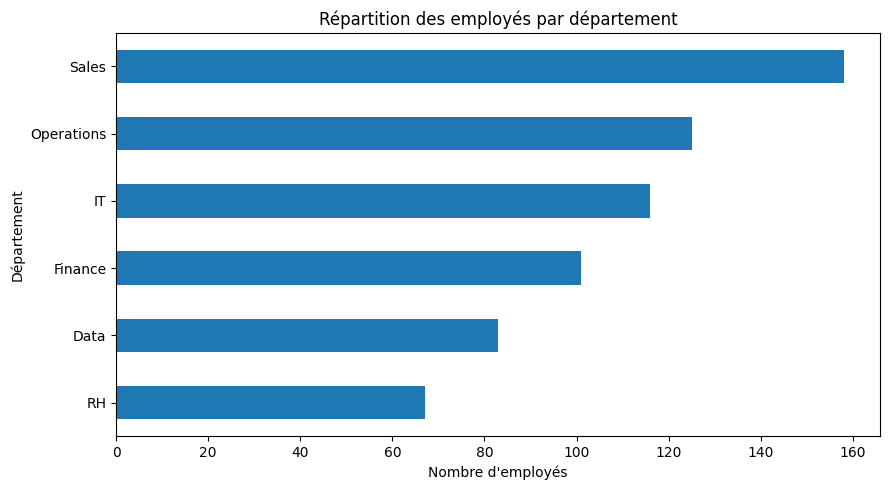

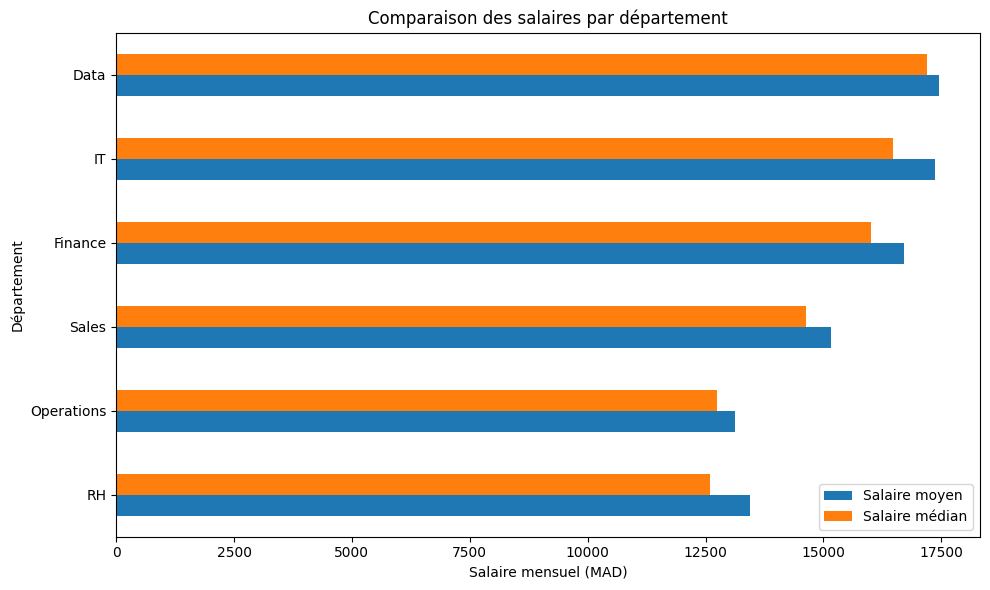

In [15]:

# GRAPH 1 : Effectifs par département
effectifs = (analyse_departements["effectif"].sort_values())

plt.figure(figsize=(9, 5))
effectifs.plot(kind="barh")
plt.title("Répartition des employés par département")
plt.xlabel("Nombre d'employés")
plt.ylabel("Département")
plt.tight_layout()
plt.show()

# GRAPH 2 : Salaire moyen et médian par département
salaires = (analyse_departements[["salaire_moyen", "salaire_median"]].sort_values("salaire_median"))

ax = salaires.plot(kind="barh",figsize=(10, 6))
ax.set_title("Comparaison des salaires par département")
ax.set_xlabel("Salaire mensuel (MAD)")
ax.set_ylabel("Département")
ax.legend(["Salaire moyen", "Salaire médian"])
plt.tight_layout()
plt.show()


**Interprétation 1 : Répartition des employés par département**

Le département Sales est de loin le plus représenté avec environ 158 employés, suivi par 
Operations 125 et IT 116. À l'inverse, le département RH ferme la marche avec seulement 67 employés, 
soit moins de la moitié de l'effectif de Sales. Cette répartition suggère une place importante des activités commerciales et opérationnelles, 
sans permettre à elle seule de conclure sur la stratégie de l'entreprise ou l'adéquation des effectifs RH.



**Interprétation 2 : Comparaison salaire moyen vs salaire médian**

Le département Data affiche le salaire médian le plus élevé 17 200 MAD, suivi de près par IT 16 475 MAD 
et Finance 16 000 MAD, tandis que RH 12 500 MAD et Operations 12 700 MAD ferment la marche. 
Fait notable : dans le département Data, le salaire moyen 17 447 MAD est supérieur au salaire médian 17 300 MAD, 
ce qui indique que quelques salaires élevés tirent la moyenne vers le haut. 
L'écart entre salaire moyen et médian est particulièrement marqué dans IT 896 MAD d'écart 
et dans Sales 534 MAD d'écart. Ces écarts suggèrent la présence de salaires extrêmement élevés dans 
ces départements. Toutefois, les données ne permettent pas de déterminer s'il s'agit de postes de direction, de primes, 
d'ancienneté ou de tout autre facteur : c'est une piste à explorer, mais pas une conclusion. 
Cette asymétrie confirme que la médiane est un indicateur plus fiable que la moyenne pour comparer 
les niveaux de rémunération entre départements, car elle n'est pas influencée par ces valeurs extrêmes.

**Analyse des écarts salariaux entre genres et des promotions**

In [16]:

# 1- Comparaison salariale par genre
analyse_genre = (
    df_clean.groupby("gender").agg(
        effectif=("employee_id", "count"),
        salaire_moyen=("monthly_salary_mad", "mean"),
        salaire_median=("monthly_salary_mad", "median"),
        experience_mediane=("years_experience", "median")
    ).round(2))

print("=== SALAIRES PAR GENRE ===")
display(analyse_genre)

# 2- Salaires par genre et par département
analyse_genre_departement = (
    df_clean.groupby(["department", "gender"]).agg(
        effectif=("employee_id", "count"),
        salaire_median=("monthly_salary_mad", "median")).round(2))

print("\n=== SALAIRES PAR GENRE ET DÉPARTEMENT ===")
display(analyse_genre_departement)

# 3- Promotions par genre
promotions_genre = pd.crosstab(
    df_clean["gender"],
    df_clean["promoted_last_2y"])

promotions_genre["taux_promotion_pct"] = (
    promotions_genre.get("Oui", 0) / promotions_genre.sum(axis=1) * 100).round(2)

print("\n=== PROMOTIONS PAR GENRE ===")
display(promotions_genre)


=== SALAIRES PAR GENRE ===


,effectif,salaire_moyen,salaire_median,experience_mediane
gender,,,,
Femme,286,15506.12,14775.0,7.0
Homme,364,15531.32,14950.0,7.0



=== SALAIRES PAR GENRE ET DÉPARTEMENT ===


effectif  salaire_median
department gender                          
Data       Femme         37         17200.0
           Homme         46         16850.0
Finance    Femme         39         15250.0
           Homme         62         16675.0
IT         Femme         60         16300.0
           Homme         56         16650.0
Operations Femme         58         13025.0
           Homme         67         12700.0
RH         Femme         28         12900.0
           Homme         39         12400.0
Sales      Femme         64         14500.0
           Homme         94         14625.0


=== PROMOTIONS PAR GENRE ===


promoted_last_2y,Non,Oui,taux_promotion_pct
gender,,,
Femme,246,40,13.99
Homme,325,39,10.71


**Interprétation 3 : Salaires et genre**

Au niveau global, l'écart salarial entre femmes et hommes est très faible : les femmes affichent 
un salaire moyen de 15 506 MAD contre 15 531 MAD pour les hommes (soit un écart de 25 MAD, négligeable), 
et un salaire médian de 14 775 MAD contre 14 950 MAD (175 MAD d'écart). 
À noter que l'expérience professionnelle médiane est identique pour les deux groupes (7 ans). 
Toutefois, cette seule statistique ne permet pas d'exclure un effet de l'expérience ou de l'ancienneté 
sur les écarts salariaux observés.
Cependant, cette vision globale masque des disparités importantes selon le département : 
en Finance, l'écart est de 1 425 MAD en faveur des hommes (16 675 vs 15 250 MAD), tandis qu'en Data,
Operations et RH, la tendance s'inverse et les femmes perçoivent un salaire médian supérieur (+350 MAD en Data, 
+325 en Operations, +500 en RH). Limite importante : ces chiffres ne permettent pas de conclure à une 
discrimination salariale, car ils ne contrôlent ni le poste occupé, ni le niveau hiérarchique, 
ni les compétences spécifiques. Ils révèlent seulement des écarts observés à département donné, 
qui mériteraient une analyse plus fine (régression, contrôle des variables) pour être interprétés.



**Interprétation 4 : Promotions par genre**

Les femmes affichent un taux de promotion supérieur à celui des hommes : 13,99 % (40 promues sur 286) 
contre 10,71 % (39 promus sur 364), soit un écart de 3,3 points de pourcentage. En valeur absolue, 
le nombre de promotions est presque identique (40 vs 39), alors que les femmes sont minoritaires 
dans l'effectif total (286 contre 364) , ce qui renforce l'idée que les femmes sont proportionnellement 
plus souvent promues que les hommes. Cependant, plusieurs limites empêchent d'en tirer une conclusion forte:
le taux ne dit rien sur le niveau hiérarchique atteint (une promotion peut être un simple changement de grade ou 
une vraie promotion), ni sur les postes concernés, ni sur l'ancienneté requise pour être promu. 
Il est donc plus prudent de parler d'une tendance observée sur 2 ans, 
à confirmer par une analyse plus détaillée (par département, par poste, par niveau d'expérience).

**les deux dernières visualisations RH**

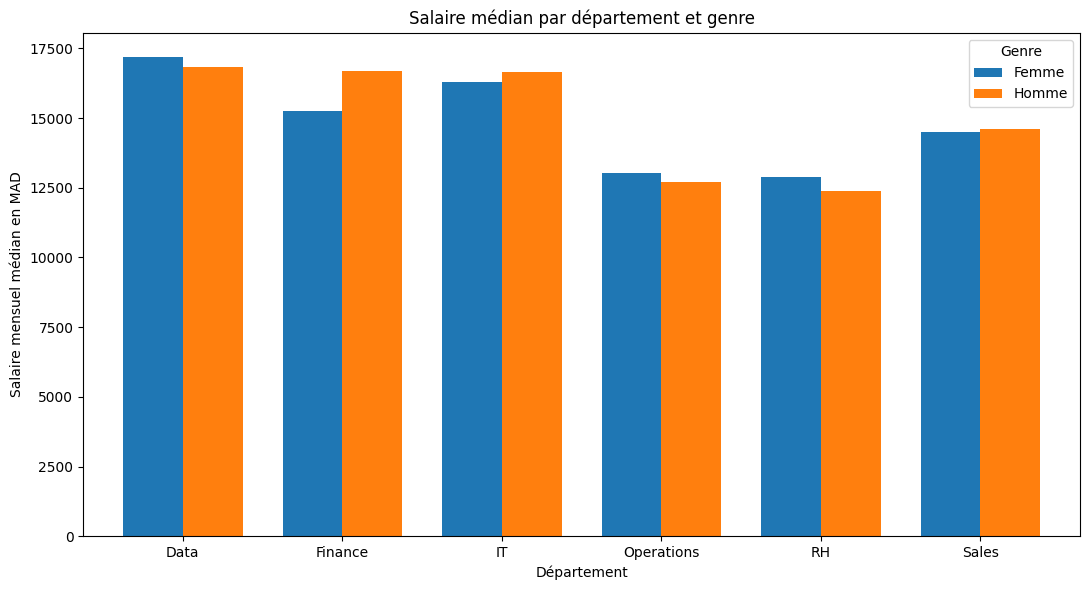

effectif  promotions  taux_promotion
department gender                                      
Data       Femme         37           5           13.51
           Homme         46           7           15.22
Finance    Femme         39           4           10.26
           Homme         62           6            9.68
IT         Femme         60          11           18.33
           Homme         56           5            8.93
Operations Femme         58           7           12.07
           Homme         67           5            7.46
RH         Femme         28           6           21.43
           Homme         39           5           12.82
Sales      Femme         64           7           10.94
           Homme         94          11            11.7

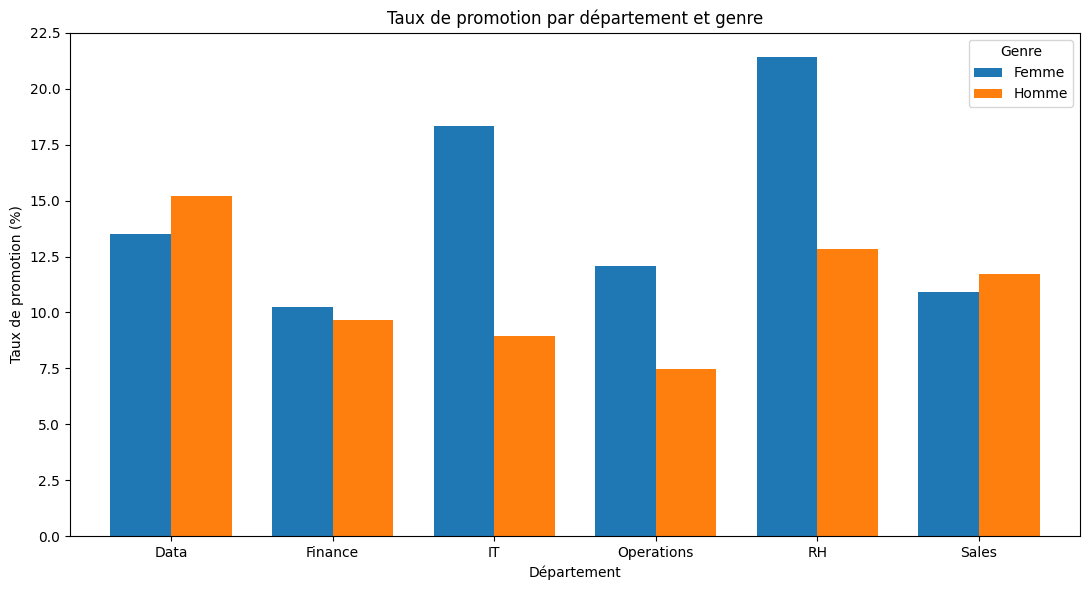

In [18]:
#Graph 3 : Salaire médian par département et genre

salaires_genre = df_clean.pivot_table(
    index="department",
    columns="gender",
    values="monthly_salary_mad",
    aggfunc="median")

ax = salaires_genre.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75)

ax.set_title("Salaire médian par département et genre")
ax.set_xlabel("Département")
ax.set_ylabel("Salaire mensuel médian en MAD")
ax.legend(title="Genre")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#Graph 4 : Taux de promotion par département et genre

    # Créer un indicateur binaire de promotion
df_clean["est_promu"] = (df_clean["promoted_last_2y"] == "Oui")

    # Calculer les taux et les effectifs
promotion_detail = (
    df_clean.groupby(["department", "gender"]).agg(
        effectif=("employee_id", "count"),
        promotions=("est_promu", "sum"),
        taux_promotion=("est_promu", "mean")))

promotion_detail["taux_promotion"] *= 100
display(promotion_detail.round(2))

    # Préparer le graphique
taux_par_departement = (
    promotion_detail["taux_promotion"].unstack("gender"))

ax = taux_par_departement.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75)
ax.set_title("Taux de promotion par département et genre")
ax.set_xlabel("Département")
ax.set_ylabel("Taux de promotion (%)")
ax.legend(title="Genre")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**Interprétation : Taux de promotion par département et genre**

L'avantage global des femmes en matière de promotion n'est pas uniforme : il masque des réalités 
départementales contrastées. Les écarts les plus importants en faveur des femmes s'observent en IT 
(18,5 % vs 9 %) et en RH (21,5 % vs 13 %), tandis que Data (13,5 % vs 15 %, écart modéré de 1,7 point) 
et Sales (11 % vs 11,8 %) présentent de légers écarts en faveur des hommes. 
En Finance et Operations, les écarts sont faibles ou modérés, avec un léger avantage féminin. 
Ces résultats montrent qu'une comparaison globale ne suffit pas à décrire les différences entre groupes: 
la tendance observée au niveau agrégé dépend fortement du département considéré. 
Une analyse complémentaire (contrôle du poste, de l'ancienneté, des effectifs par genre) serait nécessaire 
pour identifier les facteurs réellement associés aux promotions.

**Synthèse finale et recommandations RH**

*Partie A :  conclusions chiffrées*

1- Une répartition déséquilibrée des effectifs. Le département Sales concentre 158 employés, soit près de 2,4 fois l'effectif du département RH (67 employés). À eux deux, Sales et Operations totalisent 283 employés sur 650, soit 43,54 % de l'effectif total : ils occupent une place importante, sans pour autant représenter la majorité de l'entreprise. Les fonctions commerciales et opérationnelles dominent donc largement, tandis que les fonctions support (RH, Finance, Data) restent minoritaires.

2- Des écarts salariaux marqués entre départements. Le salaire médian le plus élevé est observé en Data (17 200 MAD), contre 12 600 MAD en RH, soit un écart de 4 600 MAD. Les filières techniques (Data, IT, Finance) sont nettement mieux rémunérées que les fonctions support.

3- Un écart salarial global femmes/hommes très faible, mais des disparités départementales fortes. Au niveau global, l'écart de salaire médian n'est que de 175 MAD (14 775 vs 14 950 MAD), pour une expérience médiane identique (7 ans). Mais en Finance, l'écart atteint 1 425 MAD en faveur des hommes (16 675 vs 15 250 MAD), tandis qu'en Data, Operations et RH, il s'inverse légèrement en faveur des femmes.

4- Un avantage global des femmes sur les promotions, non uniforme selon les départements. Le taux de promotion global est de 13,99 % pour les femmes contre 10,71 % pour les hommes. Cet avantage s'observe dans certains départements (IT : ~18,5 % vs ~9 % ; RH : ~21,5 % vs ~13 %), tandis qu'il s'inverse légèrement en Data (~13,5 % vs ~15 %) et Sales (~11 % vs ~11,8 %). Ces résultats montrent qu'une lecture globale ne suffit pas à décrire les différences entre groupes ; pour déterminer la contribution exacte de chaque département à l'écart global, il faudrait pondérer les taux par les effectifs et la répartition des genres dans chaque département.

*Partie B : Recommandations RH*

1- Mener un audit salarial ciblé sur le département Finance.
Constat justificatif : l'écart de salaire médian entre femmes et hommes y atteint 1 425 MAD, bien au-dessus de la moyenne globale. Une analyse fine (poste, niveau, ancienneté, performance) est nécessaire pour vérifier si cet écart relève de facteurs objectifs ou d'un biais.

2- Mettre en place un suivi genré des promotions par département.
Constat justificatif : l'avantage global des femmes (13,99 % vs 10,71 %) masque des situations inversées en Data et Sales, où les hommes sont légèrement plus promus. Un tableau de bord annuel par département permettrait de détecter ces écarts et d'agir avant qu'ils ne se creusent.

3- Réaliser une étude comparative des rémunérations par poste et niveau d'expérience.
Constat justificatif : les écarts de salaire médian entre départements (ex. Data : 17 200 MAD vs RH : 12 600 MAD) ne permettent pas de conclure à une sous-rémunération, car ils ne contrôlent ni le poste occupé, ni le niveau hiérarchique, ni l'ancienneté. Une étude comparant des postes équivalents — complétée par l'examen des résultats de satisfaction interne — serait nécessaire avant d'envisager toute mesure de revalorisation.

*Partie C : Les limites de l'analyse*

1- Des effectifs faibles et une qualité de données inégale sur certains sous-groupes.
Certaines valeurs sont manquantes ou extrêmes (salaires très élevés, 9 valeurs manquantes sur performance_score), et les croisements département × genre portent parfois sur de très petits effectifs (ex. 28 femmes en RH). Les taux calculés sur ces petits groupes sont donc sensibles aux variations aléatoires et ne peuvent pas être considérés comme stables.

2- Des variables disponibles dans le dataset mais non contrôlées dans les comparaisons.
Le dataset contient plusieurs variables pertinentes qui n'ont pas été prises en compte dans les comparaisons salariales et de promotion : le poste occupé (role), l'expérience professionnelle (years_experience), les heures hebdomadaires (weekly_hours), le score de performance (performance_score) et la date d'embauche (hire_date). Or ces facteurs peuvent expliquer une partie des écarts observés. Il manque par ailleurs une variable de niveau hiérarchique précis, qui serait utile pour affiner l'analyse. Ne pas avoir contrôlé ces variables limite donc la portée des conclusions.

3- Corrélation n'est pas causalité, et la régression ne démontre pas la causalité.
Les écarts observés (salaires, promotions) décrivent des associations entre groupes, mais ne permettent pas d'affirmer qu'ils résultent d'une discrimination ou d'un biais. Une régression multivariée permettrait de mieux étudier ces associations en tenant compte simultanément de plusieurs variables (poste, expérience, heures travaillées, performance), mais elle ne démontre pas automatiquement une relation causale. Pour établir un lien causal, il faudrait un protocole expérimental ou des méthodes quasi-expérimentales (variables instrumentales, différences en différences), qui dépassent le cadre de cette analyse.